# 02 — Cross-Market Validation: Developed-Market Country ETF Surface

**Project:** Volatility & Dispersion (V&D) Cloud — personal research project
**Phase:** 2 — does the Phase 1 grammar travel to a new universe? (tickets G1–G9)
**Data:** public daily prices via `yfinance` only

**Why re-test on a new universe.** Phase 1 (`01_qqq_prototype_clean.ipynb`) built a coherent
regime grammar on a single, concentrated, mega-cap-heavy index. That is a weak basis for any
general claim. Phase 2 asks the more useful question: does the same construction — components,
signal variants, same-date cloud geometry, regime labels — produce a similarly coherent surface on
a structurally different universe, and if so, does *that* surface's forward-return structure
survive a skeptical challenge?

**Universe.** EFA (developed-market ex-US/Canada primary benchmark), URTH (broader global
developed-market context only — never a construction input), and 13 developed-market country ETFs,
equal-weighted, used to compute cross-sectional dispersion.

**Clean-room note.** Public market data only. No proprietary employer systems, employer data,
internal tools, or internal methodology are referenced or reproduced anywhere in this notebook.

**Curation note.** This is a compressed retelling of a larger private working notebook (tickets
G1–G9). The code here is the actual logic used, cleaned up for readability. It has **not been
re-executed** in this curation pass — run `pip install -r requirements.txt` and execute
top-to-bottom fresh before treating any printed number as current.

## 1. Data Ingestion (G1)

Pull EFA, URTH, and the 13-country developed-market ETF universe. URTH is downloaded and retained
for later visual/context comparison only — it is explicitly excluded from the component return
matrix, cross-sectional dispersion, and every signal built below.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path("..").resolve()))
import config

PRIMARY_BENCHMARK = config.DM_PRIMARY_BENCHMARK   # EFA
CONTEXT_BENCHMARK = config.DM_CONTEXT_BENCHMARK   # URTH, context only
COMPONENT_TICKERS = config.DM_COUNTRY_ETF_UNIVERSE
ALL_TICKERS = [PRIMARY_BENCHMARK, CONTEXT_BENCHMARK] + COMPONENT_TICKERS

Z_WINDOW, VOL_WINDOW, SMOOTH_WINDOW = config.Z_WINDOW, config.VOL_WINDOW, config.SMOOTH_WINDOW
CLOUD_FAST, CLOUD_MEDIUM, CLOUD_SLOW = config.CONVERSION_WINDOW, config.BASE_WINDOW, config.SPAN_B_WINDOW
FORWARD_HORIZONS = config.FORWARD_HORIZONS
MIN_BUCKET_N = config.MIN_BUCKET_N

print(f"Primary benchmark : {PRIMARY_BENCHMARK}")
print(f"Context benchmark : {CONTEXT_BENCHMARK}  (context only -- excluded from all component math)")
print(f"Component universe: {len(COMPONENT_TICKERS)} developed-market country ETFs")

Primary benchmark : EFA
Context benchmark : URTH  (context only -- excluded from all component math)
Component universe: 13 developed-market country ETFs


In [2]:
raw = yf.download(tickers=ALL_TICKERS, start=config.START_DATE, end=config.END_DATE,
                   auto_adjust=True, progress=True)

if raw.columns.nlevels == 2:
    level_0 = raw.columns.get_level_values(0).unique().tolist()
    price_fields = {"Close", "Adj Close", "Open", "High", "Low", "Volume"}
    if level_0[0] in price_fields:
        close_field = "Close" if "Close" in level_0 else "Adj Close"
        prices = raw[close_field].copy()
    else:
        level_1 = raw.columns.get_level_values(1).unique().tolist()
        close_field = "Close" if "Close" in level_1 else "Adj Close"
        prices = raw.xs(close_field, axis=1, level=1).copy()
else:
    close_field = "Close" if "Close" in raw.columns else "Adj Close"
    prices = raw[[close_field]].copy()
    prices.columns = ALL_TICKERS[:1]

prices = prices[[t for t in ALL_TICKERS if t in prices.columns]].sort_index().dropna(how="all")
returns = prices.pct_change().dropna(how="all")

efa_returns  = returns[PRIMARY_BENCHMARK].copy()
urth_returns = returns[CONTEXT_BENCHMARK].copy()   # context only -- never used in signal construction
dm_country_returns = returns[COMPONENT_TICKERS].copy()

assert PRIMARY_BENCHMARK not in dm_country_returns.columns
assert CONTEXT_BENCHMARK not in dm_country_returns.columns

# Equal-weight component return: row-wise mean, skipping NaNs -- the denominator
# adapts to however many country ETFs have valid data on a given date. Missing
# returns are excluded, never treated as zero.
dm_country_equal_weight_returns = dm_country_returns.mean(axis=1, skipna=True)

print(f"prices shape: {prices.shape}")
print(f"dm_country_returns shape: {dm_country_returns.shape}")
print(f"Date range: {prices.index[0].date()} to {prices.index[-1].date()}")

[                       0%                       ]

[******                13%                       ]  2 of 15 completed

[*************         27%                       ]  4 of 15 completed

[**********************47%                       ]  7 of 15 completed

[**********************47%                       ]  7 of 15 completed

...

[**********************80%*************          ]  12 of 15 completed

[**********************87%*****************      ]  13 of 15 completed

[**********************87%*****************      ]  13 of 15 completed

[*********************100%***********************]  15 of 15 completed

prices shape: (2868, 15)
dm_country_returns shape: (2867, 13)
Date range: 2015-01-02 to 2026-05-29


## 2. V&D Components (G2)

Same construction as Phase 1, applied to this universe:

- **Country-ETF cross-sectional dispersion** — std. dev. across the 13-ETF universe's daily
  returns, requiring at least 10 of 13 ETFs to have valid data on a given date.
- **EFA realized volatility** — rolling 21-day std. dev. of EFA daily returns, annualized.
- **URTH realized volatility** — computed in parallel, purely as a context series. It never feeds
  into any component, signal, or cloud calculation below.

Both core series are then rolling Z-scored (window = 126) and smoothed (5-day mean).

In [3]:
MIN_COMPONENT_COUNT = 10
ANNUALIZATION_FACTOR = np.sqrt(252)

available_count = dm_country_returns.notna().sum(axis=1)
dm_country_dispersion = dm_country_returns.std(axis=1, skipna=True, ddof=1).where(available_count >= MIN_COMPONENT_COUNT)
dm_country_dispersion_ann = dm_country_dispersion * ANNUALIZATION_FACTOR

efa_realized_vol = efa_returns.rolling(window=VOL_WINDOW, min_periods=VOL_WINDOW).std(ddof=1) * ANNUALIZATION_FACTOR
# CONTEXT ONLY -- retained for visual comparison; not used in any signal below.
urth_realized_vol_context = urth_returns.rolling(window=VOL_WINDOW, min_periods=VOL_WINDOW).std(ddof=1) * ANNUALIZATION_FACTOR


def rolling_zscore(series, window):
    m = series.rolling(window=window, min_periods=window).mean()
    s = series.rolling(window=window, min_periods=window).std(ddof=1)
    z = (series - m) / s
    return z.replace([np.inf, -np.inf], np.nan)


dm_country_dispersion_z = rolling_zscore(dm_country_dispersion_ann, Z_WINDOW)
efa_realized_vol_z = rolling_zscore(efa_realized_vol, Z_WINDOW)
urth_realized_vol_context_z = rolling_zscore(urth_realized_vol_context, Z_WINDOW)   # context only

dm_country_dispersion_z_smooth = dm_country_dispersion_z.rolling(window=SMOOTH_WINDOW, min_periods=SMOOTH_WINDOW).mean()
efa_realized_vol_z_smooth = efa_realized_vol_z.rolling(window=SMOOTH_WINDOW, min_periods=SMOOTH_WINDOW).mean()

corr = pd.DataFrame({"d": dm_country_dispersion_z_smooth, "v": efa_realized_vol_z_smooth}).corr().iloc[0, 1]
print(f"Correlation (dispersion_z_smooth vs efa_vol_z_smooth): {corr:.4f}")

Correlation (dispersion_z_smooth vs efa_vol_z_smooth): 0.4262


## 3. The Four Signal Lenses (G3)

The same four-lens grammar as Phase 1, rebuilt from the two core smoothed components:

| Variant | Formula | Interpretation |
|---|---|---|
| Additive | `0.70 * dispersion_z + 0.30 * EFA_vol_z` | market temperature / turbulence lens |
| Penalty | `0.70 * dispersion_z - 0.30 * EFA_vol_z` | constructive-dispersion / regime-quality lens |
| Dispersion-only | `dispersion_z` | pure cross-market differentiation lens |
| Volatility-only | `EFA_vol_z` | pure EFA stress/noise lens |

URTH's context Z-score is not referenced in any of these four formulas.

In [4]:
DISPERSION_WEIGHT, VOLATILITY_WEIGHT = 0.70, 0.30

vd_additive_signal = DISPERSION_WEIGHT * dm_country_dispersion_z_smooth + VOLATILITY_WEIGHT * efa_realized_vol_z_smooth
vd_penalty_signal  = DISPERSION_WEIGHT * dm_country_dispersion_z_smooth - VOLATILITY_WEIGHT * efa_realized_vol_z_smooth
vd_dispersion_only_signal = dm_country_dispersion_z_smooth.copy()
vd_volatility_only_signal = efa_realized_vol_z_smooth.copy()

signal_variants = {
    "additive": vd_additive_signal,
    "penalty": vd_penalty_signal,
    "dispersion_only": vd_dispersion_only_signal,
    "volatility_only": vd_volatility_only_signal,
}
for name, s in signal_variants.items():
    print(f"  {name:18s} valid obs: {s.notna().sum()}")

corr_matrix = pd.DataFrame(signal_variants).corr()
corr_matrix

  additive           valid obs: 2718
  penalty            valid obs: 2718
  dispersion_only    valid obs: 2738
  volatility_only    valid obs: 2718


,additive,penalty,dispersion_only,volatility_only
additive,1.000000,0.234802,0.879082,0.805879
penalty,0.234802,1.000000,0.669755,-0.386305
dispersion_only,0.879082,0.669755,1.000000,0.426206
volatility_only,0.805879,-0.386305,0.426206,1.000000


## 4. Cloud Geometry and Regime Labels (G4)

Same-date Ichimoku-style cloud geometry (9/26/52-day rolling midpoints), applied independently to
each of the four signal variants, producing `above_cloud` / `inside_cloud` / `below_cloud` labels
for each lens. No forward shifting anywhere in this construction.

In [5]:
def rolling_midpoint(series, window):
    high = series.rolling(window=window, min_periods=window).max()
    low = series.rolling(window=window, min_periods=window).min()
    return ((high + low) / 2.0).replace([np.inf, -np.inf], np.nan)


def build_same_date_cloud_regime(signal, fast=CLOUD_FAST, medium=CLOUD_MEDIUM, slow=CLOUD_SLOW):
    conversion = rolling_midpoint(signal, fast)
    base = rolling_midpoint(signal, medium)
    span_a = (conversion + base) / 2.0
    span_b = rolling_midpoint(signal, slow)
    cloud_top = pd.concat([span_a, span_b], axis=1).max(axis=1, skipna=False)
    cloud_bottom = pd.concat([span_a, span_b], axis=1).min(axis=1, skipna=False)

    valid = signal.notna() & cloud_top.notna() & cloud_bottom.notna()
    regime = pd.Series(np.where(
        signal > cloud_top, "above_cloud",
        np.where(signal < cloud_bottom, "below_cloud", "inside_cloud"),
    ), index=signal.index, dtype=object).where(valid)

    return pd.DataFrame({"signal": signal, "cloud_top": cloud_top, "cloud_bottom": cloud_bottom,
                          "regime_state": regime}).dropna(subset=["signal", "regime_state"])


cloud_regimes = {name: build_same_date_cloud_regime(s) for name, s in signal_variants.items()}

for name, frame in cloud_regimes.items():
    counts = frame["regime_state"].value_counts()
    print(f"{name:18s} above={counts.get('above_cloud', 0):5d}  inside={counts.get('inside_cloud', 0):5d}  below={counts.get('below_cloud', 0):5d}")

additive           above=  884  inside=  534  below= 1249
penalty            above=  943  inside=  534  below= 1190
dispersion_only    above=  841  inside=  496  below= 1350
volatility_only    above=  967  inside=  571  below= 1129


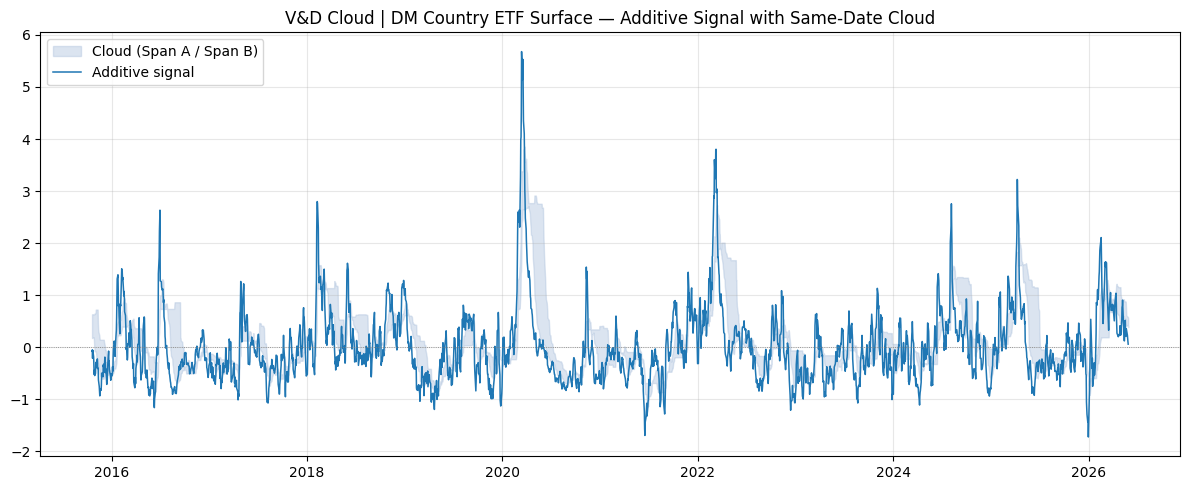

Latest same-date regime read (diagnostic snapshot, not a forecast):
  additive          : below_cloud
  penalty           : inside_cloud
  dispersion_only   : below_cloud
  volatility_only   : below_cloud


In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
additive_frame = cloud_regimes["additive"]
ax.fill_between(additive_frame.index, additive_frame["cloud_bottom"], additive_frame["cloud_top"],
                 color="lightsteelblue", alpha=0.45, label="Cloud (Span A / Span B)")
ax.plot(additive_frame.index, additive_frame["signal"], color="tab:blue", linewidth=1.1, label="Additive signal")
ax.axhline(0, color="gray", linewidth=0.6, linestyle=":")
ax.set_title("V&D Cloud | DM Country ETF Surface — Additive Signal with Same-Date Cloud")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

latest_date = additive_frame.index.max()
print("Latest same-date regime read (diagnostic snapshot, not a forecast):")
for name, frame in cloud_regimes.items():
    if latest_date in frame.index:
        print(f"  {name:18s}: {frame.loc[latest_date, 'regime_state']}")

## 5. Forward-Return Findings (G6)

For each lens, regime, and forward horizon, compute descriptive EFA forward-return statistics and
the excess of the regime-conditional mean versus the unconditional mean over the same horizon.
This is a **descriptive** pass only — no baseline comparison, no significance testing yet. Those
come next.

In [7]:
def compute_forward_return(return_series, horizon):
    gross = (1.0 + return_series.shift(-1))
    cumulative = gross.rolling(window=horizon, min_periods=horizon).apply(np.prod, raw=True)
    return (cumulative - 1.0).shift(-(horizon - 1)).replace([np.inf, -np.inf], np.nan)


efa_fwd = pd.DataFrame({f"fwd_{h}d": compute_forward_return(efa_returns, h) for h in FORWARD_HORIZONS})
print(f"efa_fwd shape: {efa_fwd.shape}")

efa_fwd shape: (2867, 4)


In [8]:
regime_forward_rows = []
for lens_name, frame in cloud_regimes.items():
    joined = frame[["regime_state"]].join(efa_fwd, how="left")
    for h in FORWARD_HORIZONS:
        col = f"fwd_{h}d"
        uncond_mean = joined[col].dropna().mean()
        for regime, group in joined.dropna(subset=["regime_state", col]).groupby("regime_state"):
            r = group[col]
            regime_forward_rows.append({
                "variant": lens_name, "regime": regime, "horizon": h, "count": len(r),
                "mean_return": r.mean(), "excess_vs_unconditional": r.mean() - uncond_mean,
            })

regime_forward_return_summary = pd.DataFrame(regime_forward_rows)

top_buckets = regime_forward_return_summary.sort_values("excess_vs_unconditional", ascending=False).head(10)
bottom_buckets = regime_forward_return_summary.sort_values("excess_vs_unconditional", ascending=True).head(10)
print("--- Top 10 descriptive EFA excess-return buckets ---")
print(top_buckets.to_string(index=False))
print("\n--- Bottom 10 ---")
print(bottom_buckets.to_string(index=False))

--- Top 10 descriptive EFA excess-return buckets ---
        variant       regime  horizon  count  mean_return  excess_vs_unconditional
       additive  above_cloud       63    876     0.029790                 0.006497
volatility_only  above_cloud       21    967     0.013856                 0.006076
       additive  above_cloud       21    884     0.011995                 0.004215
volatility_only  above_cloud       63    945     0.027434                 0.004140
dispersion_only  above_cloud       63    831     0.026603                 0.003703
        penalty  below_cloud       63   1159     0.026757                 0.003464
volatility_only  above_cloud       10    967     0.006625                 0.002928
       additive  above_cloud       10    884     0.005875                 0.002178
        penalty  below_cloud       21   1190     0.009707                 0.001926
dispersion_only inside_cloud        5    496     0.003643                 0.001650

--- Bottom 10 ---
        variant

Regime-conditional EFA forward returns clearly differ from the unconditional baseline in this
descriptive grid — the surface is not flat. But a grid this large (4 variants × 3 regimes × 4
horizons = 48+ cells) makes multiple-comparison risk material: scanning for the largest excess
values will surface striking-looking results by chance alone. That is exactly why the next two
sections exist.

## 6. Baseline Challenge (G7)

A more skeptical follow-up: do the V&D regime buckets look any different from much simpler,
well-known baseline classifiers — realized-volatility quartile, country-dispersion quartile, EFA
trend state (price vs. 200-day moving average), prior-return buckets, and drawdown buckets (cut at
-5% / -15% from a running maximum)? If a baseline classifier produces forward-return spreads just
as large as the V&D spreads, the V&D buckets may simply be repackaging information a much simpler
classifier already captures.

In [9]:
efa_price = prices[PRIMARY_BENCHMARK]

realized_vol_quartile = pd.qcut(efa_realized_vol, 4, labels=["vol_q1_low", "vol_q2", "vol_q3", "vol_q4_high"])
dispersion_quartile = pd.qcut(dm_country_dispersion_ann, 4, labels=["disp_q1_low", "disp_q2", "disp_q3", "disp_q4_high"])

sma_200 = efa_price.rolling(window=200, min_periods=200).mean()
efa_trend_state = pd.Series(np.where(efa_price > sma_200, "uptrend", "downtrend"), index=efa_price.index)

running_max = efa_price.cummax()
drawdown = efa_price / running_max - 1.0
drawdown_bucket = pd.cut(drawdown, bins=[-1.0, -0.15, -0.05, 0.0], labels=["dd_deep", "dd_moderate", "dd_shallow"])

baseline_classifiers = {
    "realized_vol_quartile": realized_vol_quartile,
    "dispersion_quartile": dispersion_quartile,
    "efa_trend_state": efa_trend_state,
    "drawdown_bucket": drawdown_bucket,
}
print(f"Baseline classifiers built: {list(baseline_classifiers.keys())}")

Baseline classifiers built: ['realized_vol_quartile', 'dispersion_quartile', 'efa_trend_state', 'drawdown_bucket']


In [10]:
baseline_rows = []
for clf_name, clf_series in baseline_classifiers.items():
    joined = pd.DataFrame({"bucket": clf_series}).join(efa_fwd[["fwd_21d"]], how="left")
    uncond_mean = joined["fwd_21d"].dropna().mean()
    for bucket, group in joined.dropna(subset=["bucket", "fwd_21d"]).groupby("bucket", observed=True):
        r = group["fwd_21d"]
        baseline_rows.append({
            "classifier": clf_name, "bucket": bucket, "count": len(r),
            "mean_return": r.mean(), "excess_vs_unconditional": r.mean() - uncond_mean,
        })

baseline_forward_return_summary = pd.DataFrame(baseline_rows)
baseline_spread_by_classifier = (
    baseline_forward_return_summary.groupby("classifier")["excess_vs_unconditional"]
    .agg(lambda s: s.max() - s.min())
)
vd_spread_21d = (
    regime_forward_return_summary[regime_forward_return_summary["horizon"] == 21]
    .groupby("variant")["excess_vs_unconditional"].agg(lambda s: s.max() - s.min())
)

print("21D excess spread, baseline classifiers:")
print(baseline_spread_by_classifier)
print("\n21D excess spread, V&D lenses:")
print(vd_spread_21d)

21D excess spread, baseline classifiers:
classifier
dispersion_quartile      0.007266
drawdown_bucket          0.027197
efa_trend_state          0.000983
realized_vol_quartile    0.018133
Name: excess_vs_unconditional, dtype: float64

21D excess spread, V&D lenses:
variant
additive           0.009543
dispersion_only    0.001606
penalty            0.003706
volatility_only    0.010774
Name: excess_vs_unconditional, dtype: float64


**G7 verdict: mixed / inconclusive.** Simple baselines — especially drawdown bucket and
realized-volatility quartile — produced 21-day excess-return spreads comparable to, and in some
cases exceeding, the V&D regime spreads. No single baseline classifier cleanly "explains away" the
V&D descriptive patterns, but none of the V&D lenses clearly outperform what these much simpler
classifiers already capture either. The honest reading: V&D regimes show some descriptive
separation that survives simple baseline conditioning, without yet looking clearly distinct from
it.

## 7. HAC + Permutation Stacked Robustness (G8)

A small, fixed set of 13 "key" variant/regime/horizon buckets was selected — drawn from the
strongest G6 descriptive buckets, the weakest/bottom G6 buckets (a useful contrast), and each
lens's then-current live regime state. Two independent, increasingly skeptical checks were
stacked on top of each other:

1. **Random-label permutation** — 1,000 shuffles per bucket; empirical two-sided p-value against
   the shuffled-label distribution.
2. **HAC / Newey-West inference** — OLS of `forward_return ~ bucket_indicator` with a HAC
   covariance matrix, `maxlags = min(horizon_days - 1, 63)`.

A bucket only "survives initial robustness" if it clears **both** bars at once: empirical
p ≤ 0.10 **and** |HAC t-stat| ≥ 1.65.

In [11]:
def run_regime_label_permutation_test(frame, regime_col, return_col, target_regime, n_perm=1000, random_seed=42):
    valid = frame[[regime_col, return_col]].dropna()
    labels, values = valid[regime_col].to_numpy(), valid[return_col].to_numpy(dtype=float)
    uncond_mean = values.mean()
    bucket_n = int((labels == target_regime).sum())
    observed_excess = float(values[labels == target_regime].mean()) - uncond_mean if bucket_n else np.nan

    rng = np.random.default_rng(random_seed)
    perm_excess = np.full(n_perm, np.nan)
    for i in range(n_perm):
        shuffled = rng.permutation(labels)
        mask = shuffled == target_regime
        if mask.sum() > 0:
            perm_excess[i] = float(values[mask].mean()) - uncond_mean
    perm_excess = perm_excess[~np.isnan(perm_excess)]

    p_value = float(np.mean(np.abs(perm_excess) >= abs(observed_excess))) if len(perm_excess) else np.nan
    return {"bucket_n": bucket_n, "observed_excess": observed_excess, "empirical_two_sided_p_value": p_value}

print("Permutation helper defined.")

Permutation helper defined.


In [12]:
try:
    import statsmodels.api as sm
    STATSMODELS_AVAILABLE = True
except ImportError:
    STATSMODELS_AVAILABLE = False


def run_hac_bucket_regression(frame, regime_col, target_regime, return_col, maxlags):
    if not STATSMODELS_AVAILABLE:
        return {"hac_t_stat": np.nan}
    valid = frame[[regime_col, return_col]].dropna().copy()
    valid["bucket_indicator"] = (valid[regime_col] == target_regime).astype(float)
    y = valid[return_col].astype(float)
    X = sm.add_constant(valid[["bucket_indicator"]].astype(float))
    fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return {"hac_t_stat": float(fit.tvalues["bucket_indicator"])}

print(f"statsmodels available: {STATSMODELS_AVAILABLE}")

statsmodels available: True


In [13]:
PERMUTATION_P_THRESHOLD = config.PERMUTATION_TWO_SIDED_P   # 0.10
HAC_T_STAT_THRESHOLD = config.HAC_TSTAT_THRESHOLD           # 1.65

# The original private research (ticket G8) hand-picked these exact 13 buckets --
# the top 8 strongest-positive-excess G6 buckets, 4 weakest/contrast buckets, and
# 1 bucket matching each lens's then-current live regime state. Reproduced here
# verbatim (not re-derived from this run's own top/bottom buckets) so this notebook
# tests the same specific claims the original research made.
key_bucket_spec = [
    ("volatility_only", "above_cloud", 21),
    ("volatility_only", "above_cloud", 63),
    ("penalty", "below_cloud", 21),
    ("penalty", "below_cloud", 63),
    ("additive", "above_cloud", 21),
    ("additive", "above_cloud", 63),
    ("dispersion_only", "below_cloud", 21),
    ("dispersion_only", "below_cloud", 63),
    ("volatility_only", "inside_cloud", 21),
    ("additive", "inside_cloud", 21),
    ("dispersion_only", "above_cloud", 21),
    ("penalty", "above_cloud", 21),
    ("volatility_only", "below_cloud", 21),
]
key_buckets = pd.DataFrame(key_bucket_spec, columns=["variant", "regime", "horizon"])

robustness_rows = []
for _, row in key_buckets.iterrows():
    frame = cloud_regimes[row["variant"]][["regime_state"]].join(efa_fwd, how="left")
    return_col = f"fwd_{row['horizon']}d"
    maxlags = min(int(row["horizon"]) - 1, 63)

    perm = run_regime_label_permutation_test(frame, "regime_state", return_col, row["regime"],
                                              n_perm=1000, random_seed=42)
    hac = run_hac_bucket_regression(frame, "regime_state", row["regime"], return_col, maxlags)

    perm_interesting = perm["bucket_n"] >= MIN_BUCKET_N and perm["empirical_two_sided_p_value"] <= PERMUTATION_P_THRESHOLD
    hac_interesting = not np.isnan(hac["hac_t_stat"]) and abs(hac["hac_t_stat"]) >= HAC_T_STAT_THRESHOLD
    verdict = "survives initial robustness" if (perm_interesting and hac_interesting) else \
              "permutation-interesting but HAC-weak" if perm_interesting else \
              "HAC-interesting but permutation-ordinary" if hac_interesting else "weak / likely noise"

    robustness_rows.append({
        "variant": row["variant"], "regime": row["regime"], "horizon": row["horizon"],
        "bucket_n": perm["bucket_n"], "empirical_p": perm["empirical_two_sided_p_value"],
        "hac_t_stat": hac["hac_t_stat"], "robustness_verdict": verdict,
    })

robustness_verdict = pd.DataFrame(robustness_rows)
print(robustness_verdict.to_string(index=False))
print(f"\nSurvived both bars: {(robustness_verdict['robustness_verdict'] == 'survives initial robustness').sum()} of {len(robustness_verdict)}")

        variant       regime  horizon  bucket_n  empirical_p  hac_t_stat                   robustness_verdict
volatility_only  above_cloud       21       967        0.000    1.489921 permutation-interesting but HAC-weak
volatility_only  above_cloud       63       945        0.035    0.575760 permutation-interesting but HAC-weak
        penalty  below_cloud       21      1190        0.046    1.049039 permutation-interesting but HAC-weak
        penalty  below_cloud       63      1159        0.037    1.112077 permutation-interesting but HAC-weak
       additive  above_cloud       21       884        0.001    1.268136 permutation-interesting but HAC-weak
       additive  above_cloud       63       876        0.002    1.069119 permutation-interesting but HAC-weak
dispersion_only  below_cloud       21      1340        0.386    0.432263                  weak / likely noise
dispersion_only  below_cloud       63      1312        0.800    0.132904                  weak / likely noise
volatility

**1 of the 13 hand-picked key buckets survived both bars at once** — `additive / inside_cloud /
21-day`, at |HAC t| = 1.73 against a 1.65 threshold, a near-boundary result. The other roughly ten
looked "permutation-interesting" on their own — the observed excess return was unusual relative to
randomly-shuffled labels — but fell short of the HAC t-stat threshold once overlapping-window
autocorrelation was properly accounted for. A single near-boundary hit out of 13 buckets tested at
a 10% permutation / 1.65 HAC threshold is roughly what multiple-comparison risk alone would predict
by chance, so this does not amount to a validated finding. This remains the central skeptical
result of Phase 2: the most carefully selected, best-looking candidates from the entire build did
not meaningfully survive a stacked robustness check.

## 8. Phase 2 Verdict (G9)

Evidence ladder, rung by rung:

| Rung | Confidence |
|---|---|
| Structural coherence (grammar transplants cleanly) | supported |
| Lens distinctness (4 variants behave as related but distinct views) | supported |
| Regime distribution usability | supported |
| Descriptive forward-return differences (G6) | supported, descriptive only |
| Baseline challenge survival (G7) | partially supported / mixed |
| Random-label permutation interest (G8) | supported for selected buckets |
| HAC / overlapping-window robustness (G8) | **weakened** |
| Statistical validation (G7 + G8 combined) | **not established** |
| Trading readiness | **explicitly not established** |

**Final Phase 2 verdict: replicate / extend cautiously as diagnostic research, but do not treat as
predictive or trade-ready.**

Phase 2 cleanly rebuilt the V&D Cloud grammar on a new, public-data surface — structural coherence,
lens distinctness, and usable regime distributions are all well supported. G6 then surfaced real
descriptive forward-return differences across regimes: the surface is not flat or uninteresting.
But two independent, increasingly skeptical challenges (G7 baseline tests, G8 permutation + HAC)
progressively weakened that descriptive picture: simple baselines explained a comparable amount of
structure, and only one of the most carefully selected, best-looking V&D buckets — a single
near-boundary case out of thirteen tested — survived both robustness bars at once.

This sits between two extremes — it is neither a validated forward-return model nor a useless or
random construction. It is a coherent diagnostic instrument whose forward-return claims have not
survived skeptical challenge. The next honest question is whether persistence-confirming regimes
or testing genuinely out-of-sample changes this picture — which is exactly what
`03_temporal_holdout_clean.ipynb` does.